# Wettereinfluss auf den Radverkehr in Berlin – Analyse
Daten: stündliche Zählstellen-Werte 2023–2025 (Senatsverwaltung) und Wetter der DWD-Station Berlin-Tempelhof (über Bright Sky), geladen aus MariaDB.
Wetterwert mit Zeitstempel 9:00 gehört zur Zählstunde 8–9 Uhr. Regenstunde = mindestens 0,1 mm Niederschlag.

In [3]:
import sys; sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from src.load.datenbank import abfrage

## Daten laden
Nur gültige Zählwerte (`ok`, `rekonstruiert`). Stunden mit fehlenden Wetterwerten werden entfernt (keine Imputation).

In [4]:
df = abfrage("""
SELECT z.zaehlstelle_code, s.streckentyp, z.zeitpunkt, z.anzahl, z.qualitaet,
       w.niederschlag_mm, w.temperatur_c, w.wind_kmh,
       f.datum IS NOT NULL AS feiertag
FROM zaehlung z
JOIN zaehlstelle s ON s.zaehlstelle_code = z.zaehlstelle_code
JOIN wetter w ON w.zeitpunkt = z.zeitpunkt + INTERVAL 1 HOUR
LEFT JOIN feiertag f ON f.datum = DATE(z.zeitpunkt)
WHERE z.qualitaet IN ('ok','rekonstruiert')
""")
df.shape, df.anzahl.isna().sum()

((857400, 9), np.int64(0))

In [6]:
df = df.dropna(subset=["niederschlag_mm", "temperatur_c", "wind_kmh"])
df["stunde"] = df.zeitpunkt.dt.hour
df["wochentag"] = df.zeitpunkt.dt.day_of_week   # Mo = 0
df["monat"] = df.zeitpunkt.dt.month
df["regen"] = df.niederschlag_mm >= 0.1
len(df), df.regen.mean()

(851996, np.float64(0.08549453283818234))

851.996 Zählstunden, davon 8,6 % mit Regen.

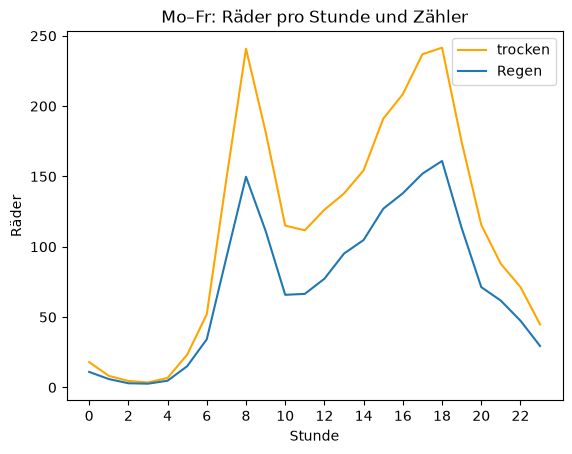

In [17]:
t = df[(df.wochentag < 5) & (df.feiertag == 0)]
t.groupby(["stunde", "regen"]).anzahl.mean().unstack().rename(columns={False: "trocken", True: "Regen"}).plot(title="Mo–Fr: Räder pro Stunde und Zähler", xlabel="Stunde", ylabel="Räder", xticks=range(0, 24, 2), color=["orange", "tab:blue"])
plt.legend(title=None)
plt.show()

An Werktagen zeigt der Radverkehr zwei Spitzen (ca. 8 und 17 Uhr). Bei Regen liegt die Kurve durchgehend niedriger.

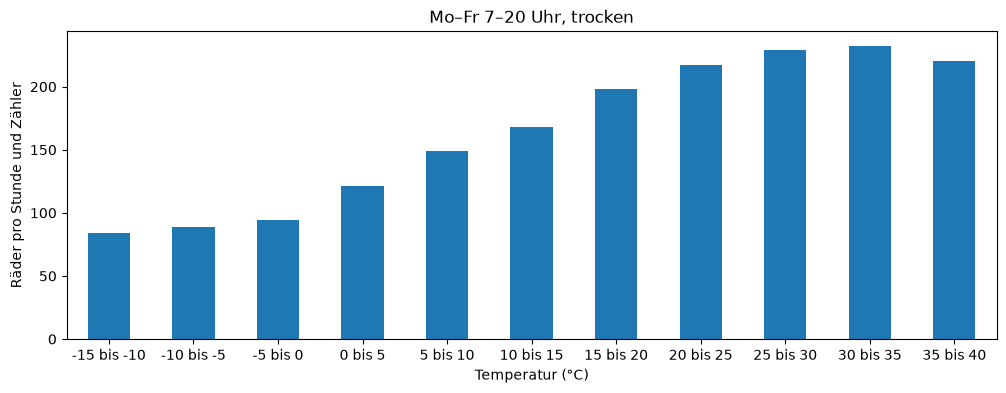

In [24]:
tag = t[t.stunde.between(7, 19) & ~t.regen]
s = tag.groupby(tag.temperatur_c // 5 * 5).anzahl.mean()
s.index = [f"{k:.0f} bis {k + 5:.0f}" for k in s.index]
s.plot(kind="bar", rot=0, figsize=(12, 4), title="Mo–Fr 7–20 Uhr, trocken", xlabel="Temperatur (°C)", ylabel="Räder pro Stunde und Zähler")
plt.show()

Bei trockenem Wetter steigt der Radverkehr tagsüber mit der Temperatur (bis max. 35°C).

## H1: Regen und Kälte senken den Radverkehr
Lineare Regression auf log(Anzahl + 1) mit allen Zählstellen, kontrolliert für Stunde, Wochentag, Monat, Feiertag und Zählstelle. Koeffizienten werden in Prozent umgerechnet.

In [25]:
import numpy as np
import statsmodels.formula.api as smf
m = smf.ols("np.log1p(anzahl) ~ regen + temperatur_c + wind_kmh + feiertag + C(stunde) + C(wochentag) + C(monat) + C(zaehlstelle_code)", data=df).fit()
print(m.rsquared)
np.expm1(m.params[["regen[T.True]", "temperatur_c", "wind_kmh", "feiertag"]]) * 100

0.8374771139864068


regen[T.True]   -28.824096
temperatur_c      2.934106
wind_kmh         -0.595912
feiertag        -47.779428
dtype: float64

**H1 bestätigt.** Regen: -29 %, je °C wärmer: +2,9 %, je km/h Wind: -0,6 %, Feiertag: -48 % (R² = 0,84).
Der rohe Regenunterschied (-36 %) ist kleiner, sobald Uhrzeit und Saison berücksichtigt werden.

## H2: Ist der Regeneffekt in Ausgehnächten schwächer als im Berufsverkehr?
Vier Orte, Ost- und Westrichtung summiert: Oberbaumbrücke, Maybachufer (Ausgehstrecken), Karl-Marx-Allee, Invalidenstraße (Pendlerstrecken). Eine Stunde zählt nur, wenn alle Richtungen gültig sind.
- **Berufsverkehr:** Mo-Fr, 7-9 Uhr, ohne Feiertage
- **Ausgehnacht:** Sa und So, 0-5 Uhr (Nächte Fr→Sa und Sa→So)
- **Werktagsnacht (Vergleich):** Di-Fr, 0-5 Uhr

In [28]:
ort = {"05-FK-OBB-O": "Oberbaumbrücke", "05-FK-OBB-W": "Oberbaumbrücke", "21-NK-MAY": "Maybachufer",
       "01-MI-AL-W": "Karl-Marx-Allee", "03-MI-SAN-O": "Invalidenstraße", "03-MI-SAN-W": "Invalidenstraße"}
h = df[df.zaehlstelle_code.isin(ort)].copy()
h["ort"] = h.zaehlstelle_code.map(ort)
g = h.groupby(["ort", "zeitpunkt", "stunde", "wochentag", "feiertag", "regen"]).anzahl.agg(["sum", "size"]).reset_index()
g = g[g["size"] == g.groupby("ort")["size"].transform("max")]
g["fenster"] = ""
g.loc[(g.wochentag < 5) & g.stunde.isin([7, 8]) & (g.feiertag == 0), "fenster"] = "Berufsverkehr"
g.loc[(g.wochentag >= 5) & (g.stunde <= 4), "fenster"] = "Ausgehnacht"
g.loc[g.wochentag.between(1, 4) & (g.stunde <= 4), "fenster"] = "Werktagsnacht"
w = g[g.fenster != ""]
e = w.groupby(["fenster", "ort", "regen"])["sum"].mean().unstack()
e["effekt_%"] = (e[True] / e[False] - 1) * 100
e["regenstunden"] = w.groupby(["fenster", "ort"]).regen.sum()
e.round(1)

regen                          False   True  effekt_%  regenstunden
fenster       ort                                                  
Ausgehnacht   Invalidenstraße   29.7   17.2     -42.2           136
              Karl-Marx-Allee   17.7    8.7     -51.1           136
              Maybachufer       45.1   28.9     -36.0           136
              Oberbaumbrücke   154.2   86.2     -44.1           136
Berufsverkehr Invalidenstraße  387.8  248.3     -36.0           144
              Karl-Marx-Allee  449.6  256.8     -42.9           144
              Maybachufer      314.7  229.7     -27.0           144
              Oberbaumbrücke   655.3  444.1     -32.2           144
Werktagsnacht Invalidenstraße   17.2   11.5     -32.8           227
              Karl-Marx-Allee    9.9    5.8     -40.9           227
              Maybachufer       17.1   11.3     -34.0           227
              Oberbaumbrücke    60.7   36.9     -39.3           227

Ohne Kontrollen ist der Regeneffekt in der Ausgehnacht an allen vier Orten **stärker** als im Berufsverkehr (z. B. Oberbaumbrücke -44 % vs. -32 %). H2 wird damit nicht gestützt. Mögliche Erklärung: Pendler sind auf das Rad angewiesen, nachts gibt es Alternativen oder man bleibt zu Hause.
Ausgehstrecken reagieren generell schwächer auf Regen als Pendlerstrecken.